In [2]:
#manipulacao data
import numpy as np
import pandas as pd
import pandas_datareader.data as web

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.mlab as mlab

#calculo estatistica
from scipy.stats import norm

import pylab as pl
import datetime as dt

import yfinance as yf
yf.pdr_override

from tabulate import tabulate

In [3]:
df_1 = pd.DataFrame()
df_2 = pd.DataFrame()
df_1 = web.DataReader('ITUB4.SA', data_source='yahoo', start='1-1-2015')
df_2 = web.DataReader('PETR4.SA', data_source='yahoo', start='1-1-2015')

<AxesSubplot:xlabel='Date'>

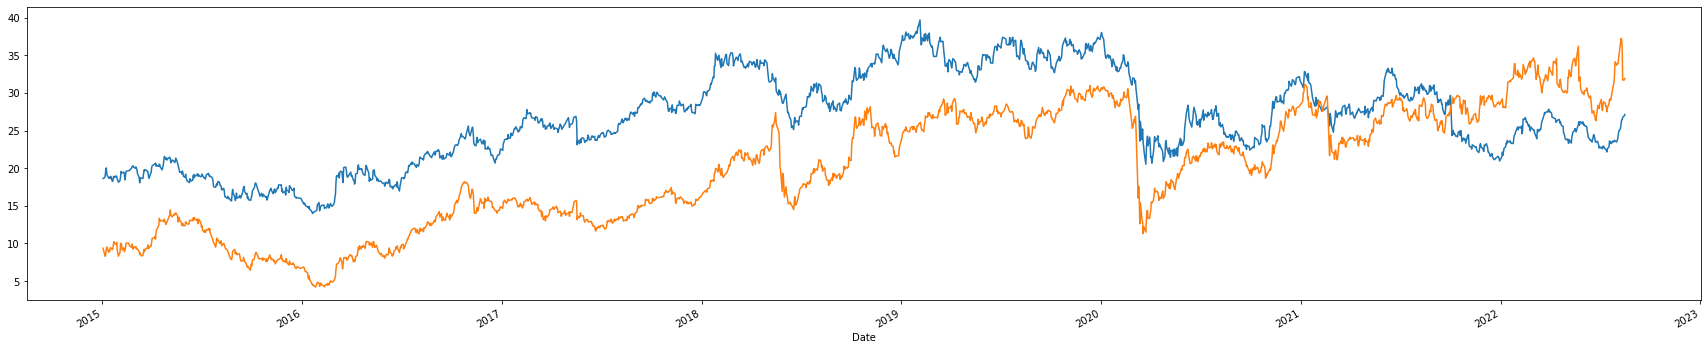

In [4]:
df_1["Close"].plot(figsize=(30,6),label='ITUB4')
df_2["Close"].plot(figsize=(30,6), label = 'PETR4')


In [5]:
df_1['retorno_simp'] = df_1['Adj Close'].pct_change()
df_2['retorno_simp'] = df_2['Adj Close'].pct_change()
print(df_1.tail())
print(df_2.tail())

                 High        Low       Open      Close      Volume  Adj Close  \
Date                                                                            
2022-08-10  26.500000  25.900000  26.160000  26.379999  48570000.0  26.379999   
2022-08-11  26.780001  26.330000  26.629999  26.420000  40492400.0  26.420000   
2022-08-12  26.790001  26.370001  26.590000  26.740000  38089200.0  26.740000   
2022-08-15  27.110001  26.340000  26.340000  26.969999  36567300.0  26.969999   
2022-08-16  27.240000  26.629999  26.940001  27.129999   2977900.0  27.129999   

            retorno_simp  
Date                      
2022-08-10      0.018533  
2022-08-11      0.001516  
2022-08-12      0.012112  
2022-08-15      0.008601  
2022-08-16      0.005933  
                 High        Low       Open      Close       Volume  \
Date                                                                  
2022-08-10  37.650002  36.610001  37.650002  37.110001   78369600.0   
2022-08-11  37.860001  36.2500

In [6]:
df_1

,High,Low,Open,Close,Volume,Adj Close,retorno_simp
Date,,,,,,,
2015-01-02,19.179064,18.468319,18.870523,18.639118,20756703.0,13.490841,NaN
2015-01-05,18.925619,18.203856,18.347107,18.732782,23532382.0,13.558640,0.005026
2015-01-06,19.035812,18.528925,18.732782,19.035812,27725577.0,13.777966,0.016176
2015-01-07,20.022038,19.283747,19.283747,19.724518,23601897.0,14.276438,0.036179
2015-01-08,20.110191,19.404959,19.834709,20.033056,21403024.0,14.499765,0.015643
...,...,...,...,...,...,...,...
2022-08-10,26.500000,25.900000,26.160000,26.379999,48570000.0,26.379999,0.018533
2022-08-11,26.780001,26.330000,26.629999,26.420000,40492400.0,26.420000,0.001516
2022-08-12,26.790001,26.370001,26.590000,26.740000,38089200.0,26.740000,0.012112


<AxesSubplot:xlabel='Date'>

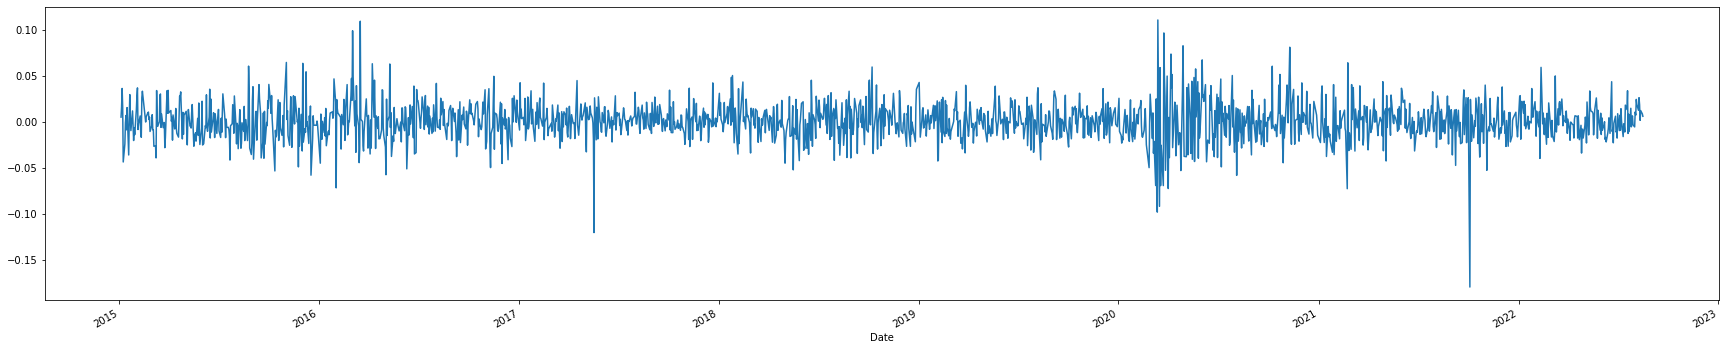

In [7]:
df_1["retorno_simp"].plot(figsize=(30,6))


<AxesSubplot:xlabel='Date'>

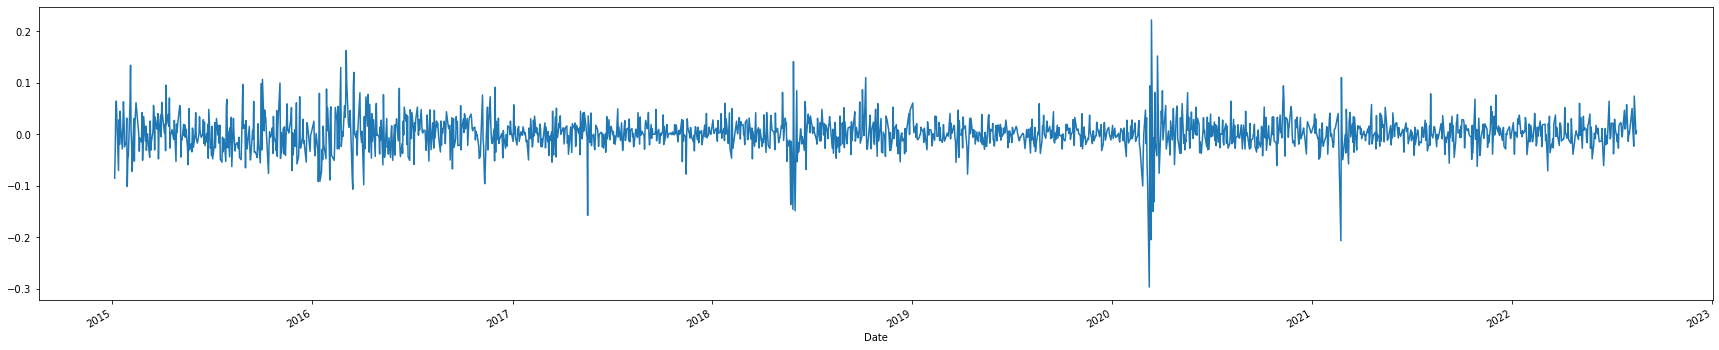

In [8]:
df_2["retorno_simp"].plot(figsize=(30,6))

In [9]:
std_1 = df_1['Adj Close'].std()
print(std_1)
std_2 = df_2['Adj Close'].std()
print(std_2)


6.477070755360356
5.486519983076474


In [10]:
#fit = stats.norm.pdf(retorno, np.mean(retorno), np.std(retorno)) 
#plt.hist(retorno.values,100)

mean = np.mean(df_1['retorno_simp'])
std_dev = np.std(df_1['retorno_simp'])

mean2 = np.mean(df_2['retorno_simp'])
std_dev2 = np.std(df_2['retorno_simp'])
""" df['retorno_simp'].hist(bins=40, normed=True, histtype='stepfilled', alpha=0.5)
x = np.linspace(mean - 3*std_dev, mean + 3*std_dev, 100)
plt.plot(x, mlab.normpdf(x, mean, std_dev), "r")
plt.show() """

' df[\'retorno_simp\'].hist(bins=40, normed=True, histtype=\'stepfilled\', alpha=0.5)\nx = np.linspace(mean - 3*std_dev, mean + 3*std_dev, 100)\nplt.plot(x, mlab.normpdf(x, mean, std_dev), "r")\nplt.show() '

In [11]:
import plotly.express as px

fig = px.histogram(df_1, x="retorno_simp")
fig.show()
fig = px.histogram(df_2, x="retorno_simp")
fig.show()

In [12]:
norm.ppf(1-0.95,0,1)

-1.6448536269514722

In [13]:
VaR_90 = norm.ppf(1-0.9, mean, std_dev)
VaR_95 = norm.ppf(1-0.95, mean, std_dev)
VaR_99 = norm.ppf(1-0.99, mean, std_dev)

print (tabulate([["90%", VaR_90],["95%", VaR_95],["99%", VaR_99]], headers=['Valor de confianca', 'VaR Par']))

VaR_90 = norm.ppf(1-0.9, mean2, std_dev2)
VaR_95 = norm.ppf(1-0.95, mean2, std_dev2)
VaR_99 = norm.ppf(1-0.99, mean2, std_dev2)

print (tabulate([["90%", VaR_90],["95%", VaR_95],["99%", VaR_99]], headers=['Valor de confianca', 'VaR Par']))

Valor de confianca       VaR Par
--------------------  ----------
90%                   -0.0261415
95%                   -0.0337188
99%                   -0.0479324
Valor de confianca       VaR Par
--------------------  ----------
90%                   -0.0396177
95%                   -0.0512835
99%                   -0.0731667


In [14]:
df_1.sort_values('retorno_simp', inplace= True, ascending= True)
print(df_1)
df_2.sort_values('retorno_simp', inplace= True, ascending= True)
print(df_2)

                 High        Low       Open      Close       Volume  \
Date                                                                  
2021-10-04  24.809999  23.840000  24.750000  24.340000   58942600.0   
2017-05-18  23.959999  21.133333  21.133333  23.120001  104917200.0   
2020-03-12  24.559999  22.410000  23.200001  23.600000   58487200.0   
2020-03-16  25.660000  22.719999  23.500000  23.799999   62416000.0   
2020-03-11  28.139999  25.030001  27.799999  26.170000   48242100.0   
...               ...        ...        ...        ...          ...   
2020-03-24  23.280001  21.500000  21.700001  22.500000   51467700.0   
2016-03-03  18.163635  16.660606  16.666666  18.115150   69189780.0   
2016-03-17  20.290909  18.963636  19.757574  20.060606   61577010.0   
2020-03-13  27.180000  23.650000  26.940001  26.209999   89695700.0   
2015-01-02  19.179064  18.468319  18.870523  18.639118   20756703.0   

            Adj Close  retorno_simp  
Date                                 


In [15]:
VaR_90_hist = df_1['retorno_simp'].quantile(0.1)
VaR_95_hist = df_1['retorno_simp'].quantile(0.05)
VaR_99_hist = df_1['retorno_simp'].quantile(0.01)

print (tabulate([["90%", VaR_90_hist],["95%", VaR_95_hist],["99%", VaR_99_hist]], headers=['Valor de confianca', 'VaR Hist']))

VaR_90_hist = df_2['retorno_simp'].quantile(0.1)
VaR_95_hist = df_2['retorno_simp'].quantile(0.05)
VaR_99_hist = df_2['retorno_simp'].quantile(0.01)

print (tabulate([["90%", VaR_90_hist],["95%", VaR_95_hist],["99%", VaR_99_hist]], headers=['Valor de confianca', 'VaR Hist']))

Valor de confianca      VaR Hist
--------------------  ----------
90%                   -0.0224805
95%                   -0.0308536
99%                   -0.0512915
Valor de confianca      VaR Hist
--------------------  ----------
90%                   -0.0319534
95%                   -0.0448555
99%                   -0.085716


In [16]:
#funcao para periodo de tempo
# t = 21 rolling(t)
#calcular stress "diferenca de porcentagem"

In [17]:
df_1.index

DatetimeIndex(['2021-10-04', '2017-05-18', '2020-03-12', '2020-03-16',
               '2020-03-11', '2021-02-22', '2020-04-01', '2016-02-02',
               '2020-03-18', '2020-03-23',
               ...
               '2015-11-03', '2020-06-02', '2020-04-06', '2020-11-09',
               '2020-04-28', '2020-03-24', '2016-03-03', '2016-03-17',
               '2020-03-13', '2015-01-02'],
              dtype='datetime64[ns]', name='Date', length=1895, freq=None)

In [18]:
#stress_1du = df.loc["2021-10-04","retorno_simp"]
stress_1du= df_1.iloc[0,6] * 100  #iloc[ : , : ]
print(*["O stress para 1DU",stress_1du,"%"])

stress_1du= df_2.iloc[0,6] * 100
print(*["O stress para 1DU",stress_1du,"%"])
df_1.iloc[0,6]

O stress para 1DU -17.96428199508 %
O stress para 1DU -29.697755206757435 %


-0.1796428199508

In [19]:
df_1.sort_values('Date', inplace= True, ascending= True)
df_1

,High,Low,Open,Close,Volume,Adj Close,retorno_simp
Date,,,,,,,
2015-01-02,19.179064,18.468319,18.870523,18.639118,20756703.0,13.490841,NaN
2015-01-05,18.925619,18.203856,18.347107,18.732782,23532382.0,13.558640,0.005026
2015-01-06,19.035812,18.528925,18.732782,19.035812,27725577.0,13.777966,0.016176
2015-01-07,20.022038,19.283747,19.283747,19.724518,23601897.0,14.276438,0.036179
2015-01-08,20.110191,19.404959,19.834709,20.033056,21403024.0,14.499765,0.015643
...,...,...,...,...,...,...,...
2022-08-10,26.500000,25.900000,26.160000,26.379999,48570000.0,26.379999,0.018533
2022-08-11,26.780001,26.330000,26.629999,26.420000,40492400.0,26.420000,0.001516
2022-08-12,26.790001,26.370001,26.590000,26.740000,38089200.0,26.740000,0.012112


In [20]:
df_2.sort_values('Date', inplace= True, ascending= True)
df_2

,High,Low,Open,Close,Volume,Adj Close,retorno_simp
Date,,,,,,,
2015-01-02,9.990000,9.350000,9.990000,9.360000,49559500.0,4.714057,NaN
2015-01-05,9.190000,8.530000,9.140000,8.560000,78385100.0,4.311146,-0.085470
2015-01-06,8.830000,8.040000,8.710000,8.280000,84723300.0,4.170127,-0.032710
2015-01-07,8.730000,8.360000,8.560000,8.670000,85531000.0,4.366547,0.047102
2015-01-08,9.390000,8.740000,8.790000,9.230000,83306300.0,4.648585,0.064591
...,...,...,...,...,...,...,...
2022-08-10,37.650002,36.610001,37.650002,37.110001,78369600.0,30.218287,-0.003223
2022-08-11,37.860001,36.250000,37.450001,36.250000,128896500.0,29.517998,-0.023174
2022-08-12,31.830000,29.080000,29.100000,31.709999,171288300.0,31.709999,0.074260


In [21]:
s21_1=df_1[['retorno_simp']].rolling(21).sum().dropna()
s21_1.sort_values(by='retorno_simp')

s21_2=df_2[['retorno_simp']].rolling(21).sum().dropna()
s21_2.sort_values(by='retorno_simp')

,retorno_simp
Date,
2020-03-23,-0.824932
2020-03-18,-0.809420
2020-03-20,-0.756375
2020-03-12,-0.732866
2020-03-19,-0.725892
...,...
2016-03-29,0.602843
2016-03-18,0.622039
2016-03-21,0.642973


In [22]:
df_1.loc['2019-06-17':]

,High,Low,Open,Close,Volume,Adj Close,retorno_simp
Date,,,,,,,
2019-06-17,34.320000,33.810001,33.900002,33.950001,15638100.0,31.124550,-0.001177
2019-06-18,34.830002,34.180000,34.349998,34.830002,22791000.0,31.931322,0.025921
2019-06-19,35.490002,34.470001,34.639999,35.380001,23278900.0,32.435555,0.015791
2019-06-21,36.180000,35.500000,35.580002,36.180000,27455000.0,33.168968,0.022611
2019-06-24,36.500000,35.790001,36.240002,36.099998,22715800.0,33.095615,-0.002211
...,...,...,...,...,...,...,...
2022-08-10,26.500000,25.900000,26.160000,26.379999,48570000.0,26.379999,0.018533
2022-08-11,26.780001,26.330000,26.629999,26.420000,40492400.0,26.420000,0.001516
2022-08-12,26.790001,26.370001,26.590000,26.740000,38089200.0,26.740000,0.012112


Date
2019-06-17     998.823073
2019-06-18    1024.743840
2019-06-19    1040.534994
2019-06-21    1063.146406
2019-06-24    1060.934917
                 ...     
2022-08-01     926.866783
2022-08-02     937.518679
2022-08-03     944.685631
2022-08-04     968.963569
2022-08-05     987.762138
Name: retorno_simp, Length: 780, dtype: float64


<AxesSubplot:xlabel='Date'>

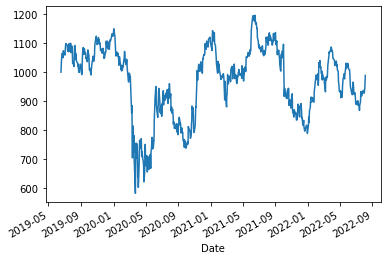

In [23]:
df_1['simp_ret_cum'] = (df_1['retorno_simp'] + 1).cumprod()-1
investimento = 1000

df_1.loc['2019-06-17':'2022-08-05','retorno_simp']
""" for i in df_1.loc['2019-06-17':'2022-08-05'
    investimento = investimento + (investimento * df_1.loc['2019-06-17':'2022-08-05','retorno_simp'])
print(investimento) """

investimento = investimento + (investimento * df_1.loc['2019-06-17':'2022-08-05','retorno_simp'].cumsum())
print(investimento)

df_1.loc['2019-06-17':]

investimento.plot()

In [24]:
df_1.loc['2019-06-17':,'retorno_simp'].cumsum()

Date
2019-06-17   -0.001177
2019-06-18    0.024744
2019-06-19    0.040535
2019-06-21    0.063146
2019-06-24    0.060935
                ...   
2022-08-10    0.044879
2022-08-11    0.046395
2022-08-12    0.058507
2022-08-15    0.067108
2022-08-16    0.073041
Name: retorno_simp, Length: 787, dtype: float64

In [25]:
preco_inicio = df_1.loc['2019-06-17','Adj Close']
print("preco dia 17-06-2019:", preco_inicio)
custodia_i = preco_inicio * 500
print("total inicio:", custodia_i)
preco_final = df_1.loc['2022-08-05','Adj Close']
print("preco dia 05-08-2022:", preco_final)
custodia_f = preco_final * 500
print("total final:", custodia_f)
retorno = custodia_f/custodia_i - 1
print("retorno em '%':",retorno*100)


preco dia 17-06-2019: 31.124549865722656
total inicio: 15562.274932861328
preco dia 05-08-2022: 24.93000030517578
total final: 12465.00015258789
retorno em '%': -19.902455095001738


In [26]:
ativos = "ITUB4.SA VIIA3.SA"

carteira = yf.download(ativos, period="5y")
carteira


[*********************100%***********************]  2 of 2 completed


Adj Close                Close                High           \
             ITUB4.SA  VIIA3.SA   ITUB4.SA VIIA3.SA   ITUB4.SA VIIA3.SA   
Date                                                                      
2017-08-16  22.109533  6.378432  26.540001     6.41  26.706667     6.41   
2017-08-17  21.931808  6.109762  26.326666     6.14  26.520000     6.40   
2017-08-18  22.142849  5.980402  26.580000     6.01  26.726665     6.32   
2017-08-21  21.981785  5.860993  26.386665     5.89  26.719999     6.01   
2017-08-22  22.448301  5.970452  26.946667     6.00  27.126665     6.10   
...               ...       ...        ...      ...        ...      ...   
2022-08-10  26.379999  2.960000  26.379999     2.96  26.500000     3.03   
2022-08-11  26.420000  2.790000  26.420000     2.79  26.780001     3.02   
2022-08-12  26.740000  3.180000  26.740000     3.18  26.790001     3.22   
2022-08-15  26.969999  3.640000  26.969999     3.64  27.110001     3.69   
2022-08-16  27.129999  3.560000  27.129999     3.56  27.240000     3.74   

                  Low                Open             Volume             
             ITUB4.SA VIIA3.SA   ITUB4.SA VIIA3.SA  ITUB4.SA   VIIA3.SA  
Date                                                                     
2017-08-16  26.240000     5.98  26.700001     6.15  17661300      13300  
2017-08-17  26.173332     5.97  26.466665     6.40  15032700      20700  
2017-08-18  26.293333     5.80  26.326666     6.31   9651900      16800  
2017-08-21  26.260000     5.86  26.580000     6.01  13419750       2000  
2017-08-22  26.546665     5.90  26.586666     6.03  15228450      13800  
...               ...      ...        ...      ...       ...        ...  
2022-08-10  25.900000     2.88  26.160000     2.90  48570000   67327500  
2022-08-11  26.330000     2.78  26.629999     2.98  40492400   67559600  
2022-08-12  26.370001     2.82  26.590000     2.82  38089200  145595100  
2022-08-15  26.340000     3.05  26.340000     3.09  36567300  120783700  
2022-08-16  26.629999     3.55  26.940001     3.72   2977900   26970100  

[1244 rows x 12 columns]

<AxesSubplot:xlabel='Date'>

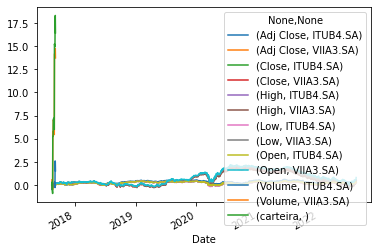

In [27]:
ret_carteira = carteira.pct_change()
ret_carteira['carteira'] = ret_carteira.sum(axis=1)
ret_carteira.cumsum().plot()

<AxesSubplot:xlabel='Date'>

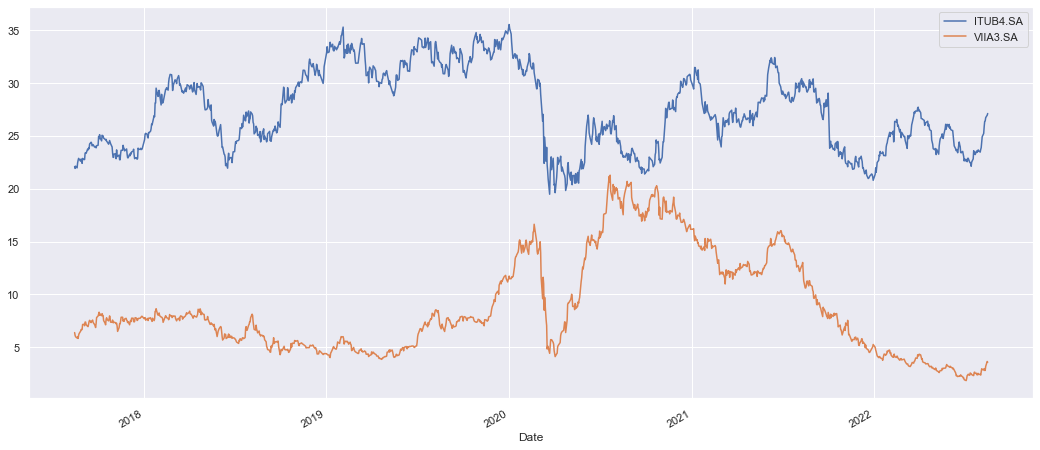

In [28]:
sns.set()
carteira['Adj Close'].plot(figsize=(18,8))

In [29]:
carteira['qtd_cotas','ITUB4.SA']= 0
carteira['qtd_cotas', 'VIIA3.SA']= 0
carteira['saldo', 'ITUB4.SA'] = 0
carteira['saldo', 'VIIA3.SA'] = 0
carteira


Adj Close                Close                High           \
             ITUB4.SA  VIIA3.SA   ITUB4.SA VIIA3.SA   ITUB4.SA VIIA3.SA   
Date                                                                      
2017-08-16  22.109533  6.378432  26.540001     6.41  26.706667     6.41   
2017-08-17  21.931808  6.109762  26.326666     6.14  26.520000     6.40   
2017-08-18  22.142849  5.980402  26.580000     6.01  26.726665     6.32   
2017-08-21  21.981785  5.860993  26.386665     5.89  26.719999     6.01   
2017-08-22  22.448301  5.970452  26.946667     6.00  27.126665     6.10   
...               ...       ...        ...      ...        ...      ...   
2022-08-10  26.379999  2.960000  26.379999     2.96  26.500000     3.03   
2022-08-11  26.420000  2.790000  26.420000     2.79  26.780001     3.02   
2022-08-12  26.740000  3.180000  26.740000     3.18  26.790001     3.22   
2022-08-15  26.969999  3.640000  26.969999     3.64  27.110001     3.69   
2022-08-16  27.129999  3.560000  27.129999     3.56  27.240000     3.74   

                  Low                Open             Volume             \
             ITUB4.SA VIIA3.SA   ITUB4.SA VIIA3.SA  ITUB4.SA   VIIA3.SA   
Date                                                                      
2017-08-16  26.240000     5.98  26.700001     6.15  17661300      13300   
2017-08-17  26.173332     5.97  26.466665     6.40  15032700      20700   
2017-08-18  26.293333     5.80  26.326666     6.31   9651900      16800   
2017-08-21  26.260000     5.86  26.580000     6.01  13419750       2000   
2017-08-22  26.546665     5.90  26.586666     6.03  15228450      13800   
...               ...      ...        ...      ...       ...        ...   
2022-08-10  25.900000     2.88  26.160000     2.90  48570000   67327500   
2022-08-11  26.330000     2.78  26.629999     2.98  40492400   67559600   
2022-08-12  26.370001     2.82  26.590000     2.82  38089200  145595100   
2022-08-15  26.340000     3.05  26.340000     3.09  36567300  120783700   
2022-08-16  26.629999     3.55  26.940001     3.72   2977900   26970100   

           qtd_cotas             saldo           
            ITUB4.SA VIIA3.SA ITUB4.SA VIIA3.SA  
Date                                             
2017-08-16         0        0        0        0  
2017-08-17         0        0        0        0  
2017-08-18         0        0        0        0  
2017-08-21         0        0        0        0  
2017-08-22         0        0        0        0  
...              ...      ...      ...      ...  
2022-08-10         0        0        0        0  
2022-08-11         0        0        0        0  
2022-08-12         0        0        0        0  
2022-08-15         0        0        0        0  
2022-08-16         0        0        0        0  

[1244 rows x 16 columns]

In [30]:
carteira.loc['2019-06-17',('qtd_cotas', 'ITUB4.SA')] = 500        #multi-index para localização de subcolunas
carteira.loc['2021-02-10',('qtd_cotas', 'VIIA3.SA')] = 1000
carteira.loc['2021-04-13',('qtd_cotas', 'ITUB4.SA')] = -300
carteira.loc['2019-06-17':'2021-02-10']


Adj Close               Close                High           \
             ITUB4.SA VIIA3.SA   ITUB4.SA VIIA3.SA   ITUB4.SA VIIA3.SA   
Date                                                                     
2019-06-17  31.124554     5.07  33.950001     5.07  34.320000     5.07   
2019-06-18  31.931318     5.07  34.830002     5.07  34.830002     5.23   
2019-06-19  32.435558     5.06  35.380001     5.06  35.490002     5.13   
2019-06-21  33.168980     5.10  36.180000     5.10  36.180000     5.16   
2019-06-24  33.095623     5.11  36.099998     5.11  36.500000     5.14   
...               ...      ...        ...      ...        ...      ...   
2021-02-04  27.112043    15.00  28.200001    15.00  28.559999    15.45   
2021-02-05  26.996675    15.08  28.080000    15.08  28.450001    15.20   
2021-02-08  26.496733    15.22  27.559999    15.22  28.200001    15.31   
2021-02-09  26.814005    14.93  27.889999    14.93  28.410000    15.47   
2021-02-10  26.621723    14.35  27.690001    14.35  28.190001    14.97   

                  Low                Open             Volume            \
             ITUB4.SA VIIA3.SA   ITUB4.SA VIIA3.SA  ITUB4.SA  VIIA3.SA   
Date                                                                     
2019-06-17  33.810001     4.98  33.900002     5.01  15638100  29082700   
2019-06-18  34.180000     5.04  34.349998     5.14  22791000  29776100   
2019-06-19  34.470001     4.96  34.639999     5.11  23278900  20698000   
2019-06-21  35.500000     5.03  35.580002     5.07  27455000  16586500   
2019-06-24  35.790001     5.07  36.240002     5.12  22715800  15109900   
...               ...      ...        ...      ...       ...       ...   
2021-02-04  27.879999    14.87  28.530001    15.10  65454600  38573500   
2021-02-05  27.889999    14.90  28.309999    15.12  39293900  28331300   
2021-02-08  27.510000    14.97  28.000000    15.15  28937500  29991600   
2021-02-09  27.230000    14.88  27.490000    15.16  37756700  32861700   
2021-02-10  27.379999    14.29  27.900000    14.94  28662100  44553700   

           qtd_cotas             saldo           
            ITUB4.SA VIIA3.SA ITUB4.SA VIIA3.SA  
Date                                             
2019-06-17       500        0        0        0  
2019-06-18         0        0        0        0  
2019-06-19         0        0        0        0  
2019-06-21         0        0        0        0  
2019-06-24         0        0        0        0  
...              ...      ...      ...      ...  
2021-02-04         0        0        0        0  
2021-02-05         0        0        0        0  
2021-02-08         0        0        0        0  
2021-02-09         0        0        0        0  
2021-02-10         0     1000        0        0  

[410 rows x 16 columns]

In [31]:
carteira.loc['2019-06-17',('saldo', 'ITUB4.SA')] = carteira.loc['2019-06-17',('Adj Close', 'ITUB4.SA')] * carteira.loc['2019-06-17',('qtd_cotas', 'ITUB4.SA')]
carteira.loc['2021-02-10',('saldo', 'VIIA3.SA')] = carteira.loc['2021-02-10',('Adj Close', 'VIIA3.SA')] * carteira.loc['2021-02-10',('qtd_cotas', 'VIIA3.SA')]
carteira.loc['2021-04-13',('saldo', 'ITUB4.SA')] = carteira.loc['2021-04-13',('Adj Close', 'ITUB4.SA')] * carteira.loc['2021-04-13',('qtd_cotas', 'ITUB4.SA')]

""" for i in enumerate(carteira.index):
    carteira['saldo'] = carteira.at[i,'qtd_cotas'] * carteira.at[i,'Adj Close'] """
#carteira['Adj Close','ITUB4.SA']
carteira
#carteira.loc['2019-06-17','qtd_cotas'] * carteira['Adj Close','ITUB4.SA']

Adj Close                Close                High           \
             ITUB4.SA  VIIA3.SA   ITUB4.SA VIIA3.SA   ITUB4.SA VIIA3.SA   
Date                                                                      
2017-08-16  22.109533  6.378432  26.540001     6.41  26.706667     6.41   
2017-08-17  21.931808  6.109762  26.326666     6.14  26.520000     6.40   
2017-08-18  22.142849  5.980402  26.580000     6.01  26.726665     6.32   
2017-08-21  21.981785  5.860993  26.386665     5.89  26.719999     6.01   
2017-08-22  22.448301  5.970452  26.946667     6.00  27.126665     6.10   
...               ...       ...        ...      ...        ...      ...   
2022-08-10  26.379999  2.960000  26.379999     2.96  26.500000     3.03   
2022-08-11  26.420000  2.790000  26.420000     2.79  26.780001     3.02   
2022-08-12  26.740000  3.180000  26.740000     3.18  26.790001     3.22   
2022-08-15  26.969999  3.640000  26.969999     3.64  27.110001     3.69   
2022-08-16  27.129999  3.560000  27.129999     3.56  27.240000     3.74   

                  Low                Open             Volume             \
             ITUB4.SA VIIA3.SA   ITUB4.SA VIIA3.SA  ITUB4.SA   VIIA3.SA   
Date                                                                      
2017-08-16  26.240000     5.98  26.700001     6.15  17661300      13300   
2017-08-17  26.173332     5.97  26.466665     6.40  15032700      20700   
2017-08-18  26.293333     5.80  26.326666     6.31   9651900      16800   
2017-08-21  26.260000     5.86  26.580000     6.01  13419750       2000   
2017-08-22  26.546665     5.90  26.586666     6.03  15228450      13800   
...               ...      ...        ...      ...       ...        ...   
2022-08-10  25.900000     2.88  26.160000     2.90  48570000   67327500   
2022-08-11  26.330000     2.78  26.629999     2.98  40492400   67559600   
2022-08-12  26.370001     2.82  26.590000     2.82  38089200  145595100   
2022-08-15  26.340000     3.05  26.340000     3.09  36567300  120783700   
2022-08-16  26.629999     3.55  26.940001     3.72   2977900   26970100   

           qtd_cotas             saldo           
            ITUB4.SA VIIA3.SA ITUB4.SA VIIA3.SA  
Date                                             
2017-08-16         0        0      0.0      0.0  
2017-08-17         0        0      0.0      0.0  
2017-08-18         0        0      0.0      0.0  
2017-08-21         0        0      0.0      0.0  
2017-08-22         0        0      0.0      0.0  
...              ...      ...      ...      ...  
2022-08-10         0        0      0.0      0.0  
2022-08-11         0        0      0.0      0.0  
2022-08-12         0        0      0.0      0.0  
2022-08-15         0        0      0.0      0.0  
2022-08-16         0        0      0.0      0.0  

[1244 rows x 16 columns]

In [32]:
print("saldo ITAU:", carteira.loc['2019-06-17',('saldo', 'ITUB4.SA')])
print("saldo VIIA:",carteira.loc['2021-02-10',('saldo', 'VIIA3.SA')])
print("desconto ITAU:",carteira.loc['2021-04-13',('saldo', 'ITUB4.SA')])

saldo ITAU: 15562.276840209961
saldo VIIA: 14350.000381469727
desconto ITAU: -7939.319801330566


In [33]:
carteira.index

DatetimeIndex(['2017-08-16', '2017-08-17', '2017-08-18', '2017-08-21',
               '2017-08-22', '2017-08-23', '2017-08-24', '2017-08-25',
               '2017-08-28', '2017-08-29',
               ...
               '2022-08-03', '2022-08-04', '2022-08-05', '2022-08-08',
               '2022-08-09', '2022-08-10', '2022-08-11', '2022-08-12',
               '2022-08-15', '2022-08-16'],
              dtype='datetime64[ns]', name='Date', length=1244, freq=None)

In [34]:
for i,data in enumerate(carteira.index):
    #print(i,data)
    carteira.iloc[i][('qtd_cotas', 'ITUB4.SA')] = carteira.iloc[i-1][('qtd_cotas', 'ITUB4.SA')] + carteira.iloc[i][('qtd_cotas', 'ITUB4.SA')]
carteira



C:\Users\giuvan.reginatto9281\AppData\Local\Temp\ipykernel_20220\1857395862.py:3: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



Adj Close                Close                High           \
             ITUB4.SA  VIIA3.SA   ITUB4.SA VIIA3.SA   ITUB4.SA VIIA3.SA   
Date                                                                      
2017-08-16  22.109533  6.378432  26.540001     6.41  26.706667     6.41   
2017-08-17  21.931808  6.109762  26.326666     6.14  26.520000     6.40   
2017-08-18  22.142849  5.980402  26.580000     6.01  26.726665     6.32   
2017-08-21  21.981785  5.860993  26.386665     5.89  26.719999     6.01   
2017-08-22  22.448301  5.970452  26.946667     6.00  27.126665     6.10   
...               ...       ...        ...      ...        ...      ...   
2022-08-10  26.379999  2.960000  26.379999     2.96  26.500000     3.03   
2022-08-11  26.420000  2.790000  26.420000     2.79  26.780001     3.02   
2022-08-12  26.740000  3.180000  26.740000     3.18  26.790001     3.22   
2022-08-15  26.969999  3.640000  26.969999     3.64  27.110001     3.69   
2022-08-16  27.129999  3.560000  27.129999     3.56  27.240000     3.74   

                  Low                Open             Volume             \
             ITUB4.SA VIIA3.SA   ITUB4.SA VIIA3.SA  ITUB4.SA   VIIA3.SA   
Date                                                                      
2017-08-16  26.240000     5.98  26.700001     6.15  17661300      13300   
2017-08-17  26.173332     5.97  26.466665     6.40  15032700      20700   
2017-08-18  26.293333     5.80  26.326666     6.31   9651900      16800   
2017-08-21  26.260000     5.86  26.580000     6.01  13419750       2000   
2017-08-22  26.546665     5.90  26.586666     6.03  15228450      13800   
...               ...      ...        ...      ...       ...        ...   
2022-08-10  25.900000     2.88  26.160000     2.90  48570000   67327500   
2022-08-11  26.330000     2.78  26.629999     2.98  40492400   67559600   
2022-08-12  26.370001     2.82  26.590000     2.82  38089200  145595100   
2022-08-15  26.340000     3.05  26.340000     3.09  36567300  120783700   
2022-08-16  26.629999     3.55  26.940001     3.72   2977900   26970100   

           qtd_cotas             saldo           
            ITUB4.SA VIIA3.SA ITUB4.SA VIIA3.SA  
Date                                             
2017-08-16         0        0      0.0      0.0  
2017-08-17         0        0      0.0      0.0  
2017-08-18         0        0      0.0      0.0  
2017-08-21         0        0      0.0      0.0  
2017-08-22         0        0      0.0      0.0  
...              ...      ...      ...      ...  
2022-08-10         0        0      0.0      0.0  
2022-08-11         0        0      0.0      0.0  
2022-08-12         0        0      0.0      0.0  
2022-08-15         0        0      0.0      0.0  
2022-08-16         0        0      0.0      0.0  

[1244 rows x 16 columns]

In [35]:
carteira[['Adj Close','qtd_cotas', 'saldo']]

Adj Close           qtd_cotas             saldo         
             ITUB4.SA  VIIA3.SA  ITUB4.SA VIIA3.SA ITUB4.SA VIIA3.SA
Date                                                                
2017-08-16  22.109533  6.378432         0        0      0.0      0.0
2017-08-17  21.931808  6.109762         0        0      0.0      0.0
2017-08-18  22.142849  5.980402         0        0      0.0      0.0
2017-08-21  21.981785  5.860993         0        0      0.0      0.0
2017-08-22  22.448301  5.970452         0        0      0.0      0.0
...               ...       ...       ...      ...      ...      ...
2022-08-10  26.379999  2.960000         0        0      0.0      0.0
2022-08-11  26.420000  2.790000         0        0      0.0      0.0
2022-08-12  26.740000  3.180000         0        0      0.0      0.0
2022-08-15  26.969999  3.640000         0        0      0.0      0.0
2022-08-16  27.129999  3.560000         0        0      0.0      0.0

[1244 rows x 6 columns]

In [36]:
operacoes = pd.DataFrame(index=carteira.index, columns=['ITUB4', 'PETR4', 'VIIA3', 'SALDO'])


In [37]:
operacoes

,ITUB4,PETR4,VIIA3,SALDO
Date,,,,
2017-08-16,NaN,NaN,NaN,NaN
2017-08-17,NaN,NaN,NaN,NaN
2017-08-18,NaN,NaN,NaN,NaN
2017-08-21,NaN,NaN,NaN,NaN
2017-08-22,NaN,NaN,NaN,NaN
...,...,...,...,...
2022-08-10,NaN,NaN,NaN,NaN
2022-08-11,NaN,NaN,NaN,NaN
2022-08-12,NaN,NaN,NaN,NaN


In [38]:
corretora = pd.DataFrame
corretora = {'2019-06-17': [('ITUB4', 'c', 500)],
            '2021-02-10': [('VIIA3', 'c', 1000)],
            '2021-09-13': [('ITUB4', 'v', 300)]
            }

In [39]:
corretora

{'2019-06-17': [('ITUB4', 'c', 500)],
 '2021-02-10': [('VIIA3', 'c', 1000)],
 '2021-09-13': [('ITUB4', 'v', 300)]}

In [40]:
valor_gasto = []
for data in corretora.keys():
    ticker = corretora[data][0][0]
    trade = corretora[data][0][1]
    qtd = corretora[data][0][2]
    preco = carteira.loc[data, f'{ticker}.SA']
    
    if trade == 'v':
        qtd = qtd*(-1)

    operacoes.loc[data, ticker] = qtd
    valor_gasto.append((ticker,qtd*preco))


KeyError: 'ITUB4.SA'

In [ ]:
valor_gasto

,ITUB4,PETR4,VIIA3,SALDO
Date,,,,
2017-08-10,NaN,NaN,NaN,NaN
2017-08-11,NaN,NaN,NaN,NaN
2017-08-14,NaN,NaN,NaN,NaN
2017-08-15,NaN,NaN,NaN,NaN
2017-08-16,NaN,NaN,NaN,NaN
...,...,...,...,...
2022-08-04,NaN,NaN,NaN,NaN
2022-08-05,NaN,NaN,NaN,NaN
2022-08-08,NaN,NaN,NaN,NaN


<AxesSubplot:xlabel='Date'>

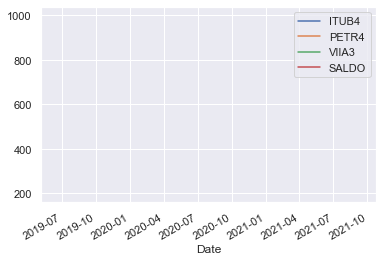

In [ ]:
operacoes.cumsum().plot()

In [ ]:
operacoes = operacoes.fillna(0).cumsum()

In [ ]:
df=pd.DataFrame()
df['itub'] = pd.DataFrame(operacoes['ITUB4']*carteira['ITUB4.SA'])

In [ ]:
df['viia3'] = pd.DataFrame(operacoes['VIIA3']*carteira['VIIA3.SA'])

In [ ]:
df['saldo'] = df['viia3'] + df['itub'] 

<AxesSubplot:xlabel='Date'>

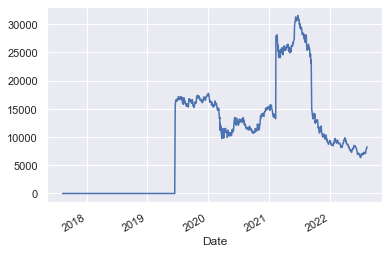

In [ ]:
df['saldo'].plot()